In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17) 
  
# data (as pandas dataframes) 
X = breast_cancer_wisconsin_diagnostic.data.features 
y = breast_cancer_wisconsin_diagnostic.data.targets 

In [4]:
X

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [6]:
y

,Diagnosis
0,M
1,M
2,M
3,M
4,M
...,...
564,M
565,M
566,M
567,M


In [8]:
y.value_counts()

Diagnosis
B            357
M            212
Name: count, dtype: int64

In [10]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-null    float64
 16  concavit

In [12]:
y.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Diagnosis  569 non-null    object
dtypes: object(1)
memory usage: 4.6+ KB


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

- make_pipeline permite construir una secuencia de pasos que se ejecutan en orden sobre los datos.
- max_iter=1000: permite al modelo realizar hasta 1000 iteraciones en el proceso de optimización.
- solver='saga': es el algoritmo utilizado para optimizar la función objetivo, necesario para usar la penalización elasticnet.
- tol=0.01: define el umbral de tolerancia para detener el entrenamiento si la mejora es pequeña.
- penalty='elasticnet': esta penalización combina L1 (Lasso) y L2 (Ridge) con un parámetro l1_ratio.

In [18]:
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter = 1000, solver = 'saga', tol = 0.01, penalty='elasticnet'))

In [20]:
# Grilla
param_grid = {'logisticregression__C': np.linspace(0.0001, 100, 10),
              'logisticregression__l1_ratio': np.linspace(0.0001, 1, 10)}

grid_search = GridSearchCV(pipe, param_grid, cv=5, n_jobs=12)

grid_search.fit(X_train, y_train)

C:\Users\josek\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('standardscaler', StandardScaler()),
                                       ('logisticregression',
                                        LogisticRegression(max_iter=1000,
                                                           penalty='elasticnet',
                                                           solver='saga',
                                                           tol=0.01))]),
             n_jobs=12,
             param_grid={'logisticregression__C': array([1.00000e-04, 1.11112e+01, 2.22223e+01, 3.33334e+01, 4.44445e+01,
       5.55556e+01, 6.66667e+01, 7.77778e+01, 8.88889e+01, 1.00000e+02]),
                         'logisticregression__l1_ratio': array([1.000e-04, 1.112e-01, 2.223e-01, 3.334e-01, 4.445e-01, 5.556e-01,
       6.667e-01, 7.778e-01, 8.889e-01, 1.000e+00])})

In [ ]:
### Un codigo similar al previo, pero con pasos más detallados

"""
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_breast_cancer
import pandas as pd

# Cargar y preparar los datos
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

# Dividir datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

# Paso 1: Escalar los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # Ajustar y transformar los datos de entrenamiento
X_test_scaled = scaler.transform(X_test)        # Solo transformar los datos de prueba

# Paso 2: Configurar el modelo de regresión logística
log_reg = LogisticRegression(
    max_iter=1000, 
    solver='saga', 
    tol=0.01, 
    penalty='elasticnet'
)

# Paso 3: Definir la grilla de hiperparámetros
param_grid = {
    'C': np.linspace(0.0001, 100, 10),
    'l1_ratio': np.linspace(0.0001, 1, 10)
}

# Paso 4: Configurar GridSearchCV para encontrar la mejor combinación de hiperparámetros
grid_search = GridSearchCV(log_reg, param_grid, cv=5, n_jobs=12)

# Paso 5: Entrenar el modelo con búsqueda en grilla usando los datos escalados
grid_search.fit(X_train_scaled, y_train)

# Resultados
print("Mejores parámetros:", grid_search.best_params_)
print("Mejor precisión en validación cruzada:", grid_search.best_score_)

# grid_search.best_score_ muestra el rendimiento (precisión, en este caso) del modelo cuando 
# se entrenó con los mejores parámetros (best_params_) en la validación cruzada.

"""

In [24]:
grid_search.best_params_

{'logisticregression__C': 55.555600000000005,
 'logisticregression__l1_ratio': 0.5556}

In [26]:
y_pred = grid_search.predict(X_test)

In [28]:
confusion_matrix(y_test, y_pred)

array([[119,   2],
       [  1,  66]], dtype=int64)

In [30]:
print(classification_report(y_test, y_pred, target_names = ['B', 'M']))

              precision    recall  f1-score   support

           B       0.99      0.98      0.99       121
           M       0.97      0.99      0.98        67

    accuracy                           0.98       188
   macro avg       0.98      0.98      0.98       188
weighted avg       0.98      0.98      0.98       188



- XGBRFClassifier es el modelo de clasificación de XGBoost que usa bosques aleatorios en lugar de boosting.
- 'reg_lambda': es el término de regularización L2. Un valor alto reduce la complejidad del modelo.
- 
'reg_alpha': es el término de regularización L1. Un valor alto puede ayudar a reducir el sobreajuste del modelo
- 
'learning_rate': es la tasa de aprendizaje. Un valor más pequeño requiere más árboles, pero puede mejorar la precisión, y un valor más alto hace que el modelo aprenda más rápido, aunque puede ser más propenso a sobreajustarse.

In [32]:
# Extreme gradient boosting

from xgboost import XGBRFClassifier

In [34]:
param_grid_xgboost = {
    'reg_lambda': np.linspace(0.0, 0.99, 5, dtype=float),
    'reg_alpha': np.linspace(0.0, 0.99, 5, dtype=float),
    'learning_rate': np.linspace(0.1, 10, 5, dtype=float)}

In [36]:
grid_search = GridSearchCV(XGBRFClassifier(), param_grid_xgboost, cv=5, n_jobs=12)

grid_search.fit(X_train, y_train)

ValueError: 
All the 625 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
625 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\josek\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\josek\anaconda3\Lib\site-packages\xgboost\core.py", line 726, in inner_f
    return func(**kwargs)
           ^^^^^^^^^^^^^^
  File "C:\Users\josek\anaconda3\Lib\site-packages\xgboost\sklearn.py", line 1712, in fit
    super().fit(**args)
  File "C:\Users\josek\anaconda3\Lib\site-packages\xgboost\core.py", line 726, in inner_f
    return func(**kwargs)
           ^^^^^^^^^^^^^^
  File "C:\Users\josek\anaconda3\Lib\site-packages\xgboost\sklearn.py", line 

In [25]:
grid_search.best_params_

{'learning_rate': 0.1, 'reg_alpha': 0.0, 'reg_lambda': 0.0}

In [26]:
y_pred_xgboost = grid_search.predict(X_test)

confusion_matrix(y_test, y_pred_xgboost)

array([[117,   4],
       [  4,  63]], dtype=int64)

In [27]:
print(classification_report(y_test, y_pred_xgboost, target_names = ['B', 'M']))

              precision    recall  f1-score   support

           B       0.97      0.97      0.97       121
           M       0.94      0.94      0.94        67

    accuracy                           0.96       188
   macro avg       0.95      0.95      0.95       188
weighted avg       0.96      0.96      0.96       188



In [31]:
X_train.shape

(381, 30)

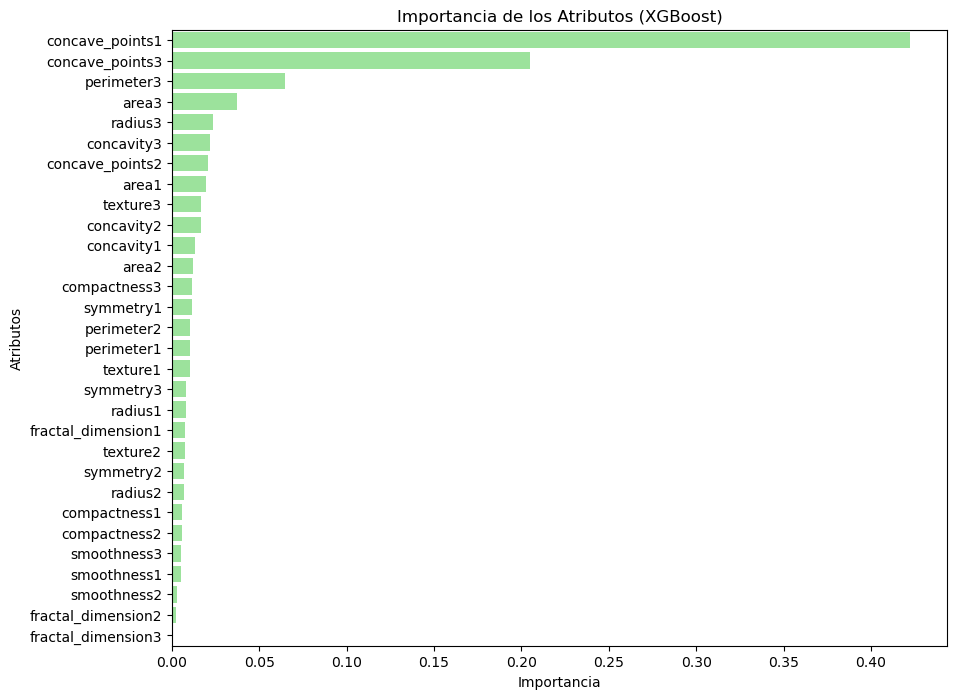

In [28]:
# Feature importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

feature_importances = grid_search.best_estimator_.feature_importances_

features = pd.Series(feature_importances, index=X.columns)

features.sort_values(ascending=False, inplace=True)

# Gráfico de la importancia de cada variable.
plt.figure(figsize = (10, 8))
sns.barplot(x = features, y = features.index, color='lightgreen')
plt.title("Importancia de los Atributos (XGBoost)")
plt.xlabel("Importancia")
plt.ylabel("Atributos")
plt.show()

In [46]:
X_2 = X[['concave_points1', 'concave_points3', 'perimeter3', 'area3']]
X_2

,concave_points1,concave_points3,perimeter3,area3
0,0.14710,0.2654,184.60,2019.0
1,0.07017,0.1860,158.80,1956.0
2,0.12790,0.2430,152.50,1709.0
3,0.10520,0.2575,98.87,567.7
4,0.10430,0.1625,152.20,1575.0
...,...,...,...,...
564,0.13890,0.2216,166.10,2027.0
565,0.09791,0.1628,155.00,1731.0
566,0.05302,0.1418,126.70,1124.0
567,0.15200,0.2650,184.60,1821.0


In [47]:
X_train, X_test, y_train, y_test = train_test_split(X_2, y, test_size=0.33, random_state=42)

In [34]:
param_grid_xgboost = {
    'reg_lambda': np.linspace(0.0, 0.99, 5, dtype=float),
    'reg_alpha': np.linspace(0.0, 0.99, 5, dtype=float),
    'learning_rate': np.linspace(0.1, 10, 5, dtype=float)}

grid_search = GridSearchCV(XGBRFClassifier(), param_grid_xgboost, cv=5, n_jobs=12)

grid_search.fit(X_train, y_train)

C:\Users\gonza\anaconda3\envs\Spyder\Lib\site-packages\sklearn\preprocessing\_label.py:97: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\gonza\anaconda3\envs\Spyder\Lib\site-packages\sklearn\preprocessing\_label.py:132: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


GridSearchCV(cv=5,
             estimator=XGBRFClassifier(base_score=None, booster=None,
                                       colsample_bylevel=None,
                                       colsample_bytree=None, gamma=None,
                                       gpu_id=None, importance_type='gain',
                                       interaction_constraints=None,
                                       max_delta_step=None, max_depth=None,
                                       min_child_weight=None, missing=nan,
                                       monotone_constraints=None,
                                       n_estimators=100, n_jobs=None,
                                       num_parallel_tree=None,
                                       objective='binary:logistic',
                                       random_state=None, reg_alpha=None,
                                       scale_pos_weight=None, tree_method=None,
                                       validate_parameters=False,
                                       verbosity=None),
             n_jobs=12,
             param_grid={'learning_rate': array([ 0.1  ,  2.575,  5.05 ,  7.525, 10.   ]),
                         'reg_alpha': array([0.    , 0.2475, 0.495 , 0.7425, 0.99  ]),
                         'reg_lambda': array([0.    , 0.2475, 0.495 , 0.7425, 0.99  ])})

In [35]:
y_pred_xgboost = grid_search.predict(X_test)

print(classification_report(y_test, y_pred_xgboost, target_names = ['B', 'M']))

              precision    recall  f1-score   support

           B       0.97      0.98      0.98       121
           M       0.97      0.94      0.95        67

    accuracy                           0.97       188
   macro avg       0.97      0.96      0.96       188
weighted avg       0.97      0.97      0.97       188



In [45]:
y_pred_xgboost = grid_search.predict(X_test)

print(classification_report(y_test, y_pred_xgboost, target_names = ['B', 'M']))

              precision    recall  f1-score   support

           B       0.95      0.90      0.92       121
           M       0.84      0.91      0.87        67

    accuracy                           0.90       188
   macro avg       0.89      0.91      0.90       188
weighted avg       0.91      0.90      0.91       188



In [48]:
# Probando estos datos con la regresión logística
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter = 1000, solver = 'saga', tol = 0.01, penalty='elasticnet'))

# Grilla
param_grid = {'logisticregression__C': np.linspace(0.0001, 100, 10),
              'logisticregression__l1_ratio': np.linspace(0.0001, 1, 10)}

grid_search = GridSearchCV(pipe, param_grid, cv=5, n_jobs=12)

grid_search.fit(X_train, y_train)

y_pred_lr = grid_search.predict(X_test)

print(classification_report(y_test, y_pred_lr, target_names = ['B', 'M']))

              precision    recall  f1-score   support

           B       0.97      0.97      0.97       121
           M       0.94      0.96      0.95        67

    accuracy                           0.96       188
   macro avg       0.96      0.96      0.96       188
weighted avg       0.96      0.96      0.96       188



C:\Users\gonza\anaconda3\envs\Spyder\Lib\site-packages\sklearn\utils\validation.py:1300: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
